# E-Commerce Product Analysis and Machine Learning

## Part 2: Classification and Machine Learning

This notebook focuses on building classification models to predict book rating categories using the cleaned Books to Scrape dataset.

### Objectives
- Prepare classification targets.
- Perform feature selection.
- Train classification algorithms.
- Evaluate and compare model performance.
- Perform cross-validation and hyperparameter tuning.
- Analyze feature importance.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

# loading cleaned dataset

In [2]:
df = pd.read_csv("../data/books_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1000, 17)


,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
0,A Light in the Attic,https://books.toscrape.com/catalogue/a-light-i...,51.77,3,In stock,22,Poetry,a897fe39b1053632,It's hard to imagine a world without A Light i...,0.0,51.77,51.77,0,True,1017,6.925595,1017.0
1,Tipping the Velvet,https://books.toscrape.com/catalogue/tipping-t...,53.74,1,In stock,20,Historical Fiction,90fa61229261140a,"""Erotic and absorbing...Written with starling ...",0.0,53.74,53.74,0,True,1029,6.937314,1029.0
2,Soumission,https://books.toscrape.com/catalogue/soumissio...,50.10,1,In stock,20,Fiction,6957f44c3847a760,"Dans une France assez proche de la nÃ´tre, un ...",0.0,50.10,50.10,0,True,1136,7.036148,1136.0
3,Sharp Objects,https://books.toscrape.com/catalogue/sharp-obj...,47.82,4,In stock,20,Mystery,e00eb4fd7b871a48,"WICKED above her hipbone, GIRL across her hear...",0.0,47.82,47.82,0,True,1647,7.407318,1647.0
4,Sapiens: A Brief History of Humankind,https://books.toscrape.com/catalogue/sapiens-a...,54.23,5,In stock,20,History,4165285e1663650f,From a renowned historian comes a groundbreaki...,0.0,54.23,54.23,0,True,1969,7.585789,1969.0


# inspecting dataset

In [3]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['title', 'product_url', 'price', 'star_rating', 'availability_status', 'stock_quantity', 'category', 'UPC', 'description', 'tax', 'price_excluding_tax', 'price_including_tax', 'number_of_reviews', 'has_description', 'description_length', 'description_length_log', 'description_length_capped']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   title                      1000 non-null   str    
 1   product_url                1000 non-null   str    
 2   price                      1000 non-null   float64
 3   star_rating                1000 non-null   int64  
 4   availability_status        1000 non-null   str    
 5   stock_quantity             1000 non-null   int64  
 6   category                   1000 non-null   str    
 7   UPC                        1000 non-null   str    
 8   descriptio

,title,product_url,price,star_rating,availability_status,stock_quantity,category,UPC,description,tax,price_excluding_tax,price_including_tax,number_of_reviews,has_description,description_length,description_length_log,description_length_capped
count,1000,1000,1000.00000,1000.000000,1000,1000.000000,1000,1000,998,1000.0,1000.00000,1000.00000,1000.0,1000,1000.000000,1000.000000,1000.000000
unique,999,1000,NaN,NaN,1,NaN,50,1000,998,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN
top,The Star-Touched Queen,https://books.toscrape.com/catalogue/a-light-i...,NaN,NaN,In stock,NaN,Default,a897fe39b1053632,It's hard to imagine a world without A Light i...,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN
freq,2,1,NaN,NaN,1000,NaN,152,1,1,NaN,NaN,NaN,NaN,998,NaN,NaN,NaN
mean,NaN,NaN,35.07035,2.923000,NaN,8.585000,NaN,NaN,NaN,0.0,35.07035,35.07035,0.0,NaN,1441.449000,7.152067,1407.368375
std,NaN,NaN,14.44669,1.434967,NaN,5.654622,NaN,NaN,NaN,0.0,14.44669,14.44669,0.0,NaN,676.500121,0.608437,535.390181
min,NaN,NaN,10.00000,1.000000,NaN,1.000000,NaN,NaN,NaN,0.0,10.00000,10.00000,0.0,NaN,0.000000,0.000000,142.125000
25%,NaN,NaN,22.10750,2.000000,NaN,3.000000,NaN,NaN,NaN,0.0,22.10750,22.10750,0.0,NaN,1074.750000,6.980773,1074.750000
50%,NaN,NaN,35.98000,3.000000,NaN,7.000000,NaN,NaN,NaN,0.0,35.98000,35.98000,0.0,NaN,1353.500000,7.211188,1353.500000
75%,NaN,NaN,47.45750,4.000000,NaN,14.000000,NaN,NaN,NaN,0.0,47.45750,47.45750,0.0,NaN,1696.500000,7.436912,1696.500000



Missing Values:
title                        0
product_url                  0
price                        0
star_rating                  0
availability_status          0
stock_quantity               0
category                     0
UPC                          0
description                  2
tax                          0
price_excluding_tax          0
price_including_tax          0
number_of_reviews            0
has_description              0
description_length           0
description_length_log       0
description_length_capped    0
dtype: int64


## 2. Classification Target Preparation

The original star rating is converted into three categories:

- Low: 1 or 2 stars
- Medium: 3 stars
- High: 4 or 5 stars

This transforms the problem into a multiclass classification task.

In [5]:
df_ml = df.copy()

def assign_rating_class(rating):
    if rating <= 2:
        return "Low"
    elif rating == 3:
        return "Medium"
    else:
        return "High"

df_ml["rating_class"] = df_ml["star_rating"].apply(assign_rating_class)

df_ml[["star_rating", "rating_class"]].head(10)

,star_rating,rating_class
0,3,Medium
1,1,Low
2,1,Low
3,4,High
4,5,High
5,1,Low
6,4,High
7,3,Medium
8,4,High
9,1,Low


# checking class distribution

In [6]:
print("Rating Class Distribution:")
print(df_ml["rating_class"].value_counts())

print("\nPercentage Distribution:")
print(df_ml["rating_class"].value_counts(normalize=True) * 100)

Rating Class Distribution:
rating_class
Low       422
High      375
Medium    203
Name: count, dtype: int64

Percentage Distribution:
rating_class
Low       42.2
High      37.5
Medium    20.3
Name: proportion, dtype: float64


# visualizing the dataset
(important ,incase lo rating books are larger in amount ,it will imbalance our model training)

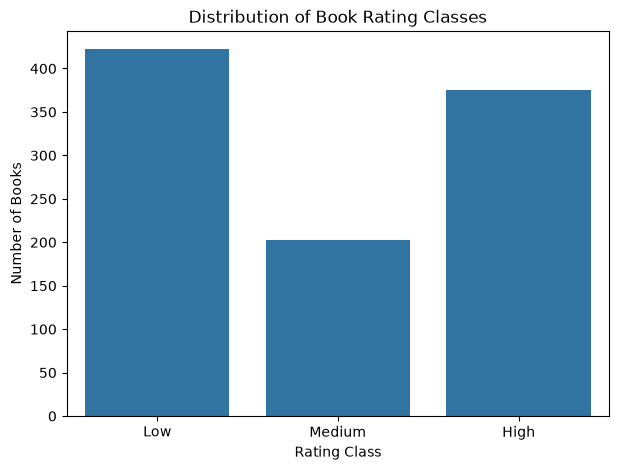

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_ml, x="rating_class", order=["Low", "Medium", "High"])

plt.title("Distribution of Book Rating Classes")
plt.xlabel("Rating Class")
plt.ylabel("Number of Books")
plt.show()

### Observations

1. The dataset contains 1,000 books.
2. Low-rated books represent 42.2% of the dataset.
3. Medium-rated books represent 20.3%.
4. High-rated books represent 37.5%.
5. The Medium class has the fewest observations.

The classes are not equally distributed. Therefore, stratified train-test splitting will be used to preserve the class proportions. Precision, recall and F1-score will also be considered during model evaluation.